
# Highway Networks - CIFAR-10 Implementation and Training

## 1. Building the Reusable Highway Layer

### 1.1 Objective

**Goal:** Implement and train a convolutional Highway Network for CIFAR-10 image classification.

We have already explored the Highway Network equations and verified that our Convolutional Highway Layer:

- Preserves input and output tensor dimensions.
- Uses independent transformation and gate parameters.
- Initially favors carrying information through negative gate bias initialization.
- Supports gradient-based optimization.

Now we move the reusable implementation into `src/highway.py`.

### 1.2 Highway Layer Equations

The Highway Layer computes:

$$
\boxed{y = H(x)T(x) + x(1-T(x))}
$$

For convolutional inputs:

$$
H(x)=\operatorname{ReLU}(\operatorname{Conv}_H(x))
$$

$$
T(x)=\sigma(\operatorname{Conv}_T(x))
$$

Both operations produce tensors with the same shape as the input.

### 1.3 Implementation Decisions

Our implementation uses:

| Component | Configuration |
|---|---|
| Transformation | `nn.Conv2d` + ReLU |
| Transform gate | `nn.Conv2d` + Sigmoid |
| Kernel size | $3\times3$ |
| Stride | 1 |
| Padding | 1 |
| Gate bias initialization | $-2.0$ |
| Carry gate | $1-T(x)$ |

The negative transform gate bias encourages the network to initially preserve more input information.

### 1.4 Separation of Responsibilities

- `src/highway.py` contains the reusable Highway Layer.
- `src/model.py` will contain the complete classification architecture.
- `03_cifar10_training.ipynb` will contain training experiments, evaluation, and visualizations.


In [1]:
import sys
from pathlib import Path

import torch
import torch.nn as nn

PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.highway import ConvHighwayLayer

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [3]:
torch.manual_seed(42)

layer = ConvHighwayLayer(
    channels=3,
    gate_bias=-2.0
).to(device)

x = torch.randn(4, 3, 32, 32, device=device)
y = layer(x)

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Output device:", y.device)

assert x.shape == y.shape
assert torch.isfinite(y).all()

Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 3, 32, 32])
Output device: cuda:0



### 1.5 Reusable Highway Layer Verification

We extracted the `ConvHighwayLayer` implementation into `src/highway.py` and imported it into the training notebook.

**Verification criteria:**

1. The layer imports successfully.
2. The layer runs on the selected computation device.
3. The output shape matches the input shape.
4. The output contains only finite values.

**Conclusion:**

The Convolutional Highway Layer is now available as a reusable component for constructing a complete CIFAR-10 classification model.



## 2. Building the Complete Highway Network Classifier

### 2.1 Objective

Our goal is to build a Convolutional Highway Network that classifies CIFAR-10 images into 10 categories.

The architecture consists of:

1. An initial convolutional layer that extracts features from RGB images.
2. Multiple Convolutional Highway Layers that learn to preserve or transform features.
3. Global average pooling to reduce spatial dimensions.
4. A fully connected classification layer producing 10 class scores.

### 2.2 Model Architecture

| Component | Input shape | Output shape |
|---|---|---|
| Input image | $(B,3,32,32)$ | $(B,3,32,32)$ |
| Initial Conv2d + ReLU | $(B,3,32,32)$ | $(B,32,32,32)$ |
| 4 Highway Layers | $(B,32,32,32)$ | $(B,32,32,32)$ |
| Global Average Pooling | $(B,32,32,32)$ | $(B,32,1,1)$ |
| Flatten | $(B,32,1,1)$ | $(B,32)$ |
| Linear Classifier | $(B,32)$ | $(B,10)$ |

Here, $B$ represents the batch size.

### 2.3 Global Average Pooling

Global average pooling converts each feature map into a single number by averaging across its spatial dimensions.

For a feature map $X_c$:

$$
z_c = \frac{1}{HW}\sum_{i=1}^{H}\sum_{j=1}^{W} X_{c,i,j}
$$

This reduces a tensor of shape:

$$
(B,C,H,W)\rightarrow(B,C,1,1)
$$

After flattening:

$$
(B,C,1,1)\rightarrow(B,C)
$$

### 2.4 Classification Output

The final linear layer produces 10 raw class scores, called **logits**:

$$
z=W_{\text{cls}}h+b_{\text{cls}}
$$

Where $h$ is the pooled feature vector.

The output shape is:

$$
\boxed{(B,10)}
$$

We do not apply softmax inside the model because PyTorch's `CrossEntropyLoss` expects raw logits.

**Important:** This is our first experimental Highway Network architecture, not an exact reproduction of the paper.


In [4]:
from src.model import HighwayCNN

torch.manual_seed(42)

model = HighwayCNN(
    num_classes=10,
    channels=32,
    num_highway_layers=4,
    gate_bias=-2.0,
).to(device)

images = torch.randn(4, 3, 32, 32, device=device)

with torch.no_grad():
    logits = model(images)

print("Input shape:", images.shape)
print("Output shape:", logits.shape)
print("Device:", logits.device)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

assert logits.shape == (4, 10)
assert torch.isfinite(logits).all()

print("Model verification passed!")

Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 10])
Device: cuda:0
Trainable parameters: 75210
Model verification passed!


In [5]:
model.zero_grad()

images = torch.randn(4, 3, 32, 32, device=device)
labels = torch.tensor([0, 1, 2, 3], device=device)

logits = model(images)

criterion = nn.CrossEntropyLoss()
loss = criterion(logits, labels)

loss.backward()

print("Loss:", loss.item())
print(
    "Classifier gradient exists:",
    model.classifier.weight.grad is not None
)
print(
    "First Highway gate gradient exists:",
    model.highway_layers[0].gate.weight.grad is not None
)

Loss: 2.3302364349365234
Classifier gradient exists: True
First Highway gate gradient exists: True



### 2.5 Model Verification

We implemented a complete Convolutional Highway Network classifier using:

- An initial convolutional feature extractor.
- Four Convolutional Highway Layers.
- Global average pooling.
- A linear classification head.

For an input batch of four CIFAR-10 images:

$$
(4,3,32,32)\rightarrow(4,10)
$$

The 10 outputs represent raw class logits.

We use `CrossEntropyLoss` for classification:

$$
\mathcal{L}=-\frac{1}{B}\sum_{i=1}^{B}\log p(y_i\mid x_i)
$$

The loss is calculated from the model's raw logits and the true class labels.

**Verification criteria:**

1. The output shape is $(B,10)$.
2. All output values are finite.
3. Cross-entropy loss can be computed.
4. Gradients reach both the classifier and Highway gate parameters.

**Conclusion:**

The model architecture is ready for CIFAR-10 dataset loading and training experiments.



## 3. Preparing the CIFAR-10 Dataset for Training

### 3.1 Dataset Overview

CIFAR-10 is an image classification dataset containing:

- 50,000 training images.
- 10,000 test images.
- 10 image classes.
- RGB images of size $32 \times 32$.

Each image has shape:

$$
(C,H,W)=(3,32,32)
$$

### 3.2 Image Normalization

We normalize each image channel using:

$$
\boxed{x_{\text{normalized}}=\frac{x-\mu}{\sigma}}
$$

Where:

- $x$ — pixel value after conversion to a tensor in $[0,1]$.
- $\mu$ — channel mean.
- $\sigma$ — channel standard deviation.

We use approximate CIFAR-10 training-set statistics:

$$
\mu=(0.4914,\ 0.4822,\ 0.4465)
$$

$$
\sigma=(0.2470,\ 0.2435,\ 0.2616)
$$

Normalization helps keep input values on a consistent scale.

### 3.3 Data Augmentation

During training, we use:

- `RandomCrop(32, padding=4)` - randomly shifts and crops an image.
- `RandomHorizontalFlip()` - randomly flips an image horizontally.
- `ToTensor()` - converts the image to a PyTorch tensor.
- `Normalize()` - standardizes the image channels.

Augmentation creates variations of training images to help improve generalization.

**Important:** We do not use random augmentation for the test dataset.

### 3.4 DataLoader

A `DataLoader` groups samples into mini-batches and optionally shuffles their order.

For batch size $B=128$, the image tensor has shape:

$$
\boxed{(128,3,32,32)}
$$

The labels have shape:

$$
(128,)
$$

Training data is shuffled each epoch, while test data is not shuffled.

The test dataset will be used to evaluate the trained model, not to update its parameters.


In [7]:
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader

CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

train_dataset = torchvision.datasets.CIFAR10(
    root=str(PROJECT_ROOT / "data"),
    train=True,
    download=True,
    transform=train_transform,
)

test_dataset = torchvision.datasets.CIFAR10(
    root=str(PROJECT_ROOT / "data"),
    train=False,
    download=True,
    transform=test_transform,
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Classes:", train_dataset.classes)

Training samples: 50000
Test samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [8]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

Training batches: 391
Test batches: 79


In [9]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Images dtype:", images.dtype)
print("Labels dtype:", labels.dtype)

print("Pixel minimum:", images.min().item())
print("Pixel maximum:", images.max().item())
print("Labels:", labels[:10].tolist())

assert images.shape == (128, 3, 32, 32)
assert labels.shape == (128,)
assert labels.min() >= 0
assert labels.max() < 10

print("DataLoader verification passed!")

Images shape: torch.Size([128, 3, 32, 32])
Labels shape: torch.Size([128])
Images dtype: torch.float32
Labels dtype: torch.int64
Pixel minimum: -1.9894737005233765
Pixel maximum: 2.12648868560791
Labels: [9, 5, 4, 3, 0, 5, 4, 7, 7, 3]
DataLoader verification passed!


In [10]:
model.eval()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    logits = model(images)
    loss = criterion(logits, labels)

print("Images:", images.shape)
print("Logits:", logits.shape)
print("Labels:", labels.shape)
print("Loss:", loss.item())

assert logits.shape == (images.shape[0], 10)
assert torch.isfinite(loss)

print("Real dataset forward pass successful!")

Images: torch.Size([128, 3, 32, 32])
Logits: torch.Size([128, 10])
Labels: torch.Size([128])
Loss: 2.3244786262512207
Real dataset forward pass successful!



### 3.5 Dataset Pipeline Verification

We prepared CIFAR-10 using separate training and test transformations.

**Training pipeline:**

1. Random crop with padding.
2. Random horizontal flip.
3. Tensor conversion.
4. Channel normalization.
5. Mini-batch loading with shuffling.

**Test pipeline:**

1. Tensor conversion.
2. Channel normalization.
3. Mini-batch loading without shuffling.


**Conclusion:**

The CIFAR-10 data pipeline is ready for model training.



## 4. Training the Highway CNN

### 4.1 Objective

We will train our Convolutional Highway Network to classify CIFAR-10 images into 10 categories.

Training consists of repeating four main operations:

1. **Forward pass:** Compute predictions from input images.
2. **Loss calculation:** Measure the difference between predictions and true labels.
3. **Backward pass:** Compute gradients using backpropagation.
4. **Optimizer step:** Update model parameters to reduce the loss.

### 4.2 Cross-Entropy Loss

For multi-class classification, we use cross-entropy loss:

$$
\boxed{
\mathcal{L}=-\frac{1}{B}\sum_{i=1}^{B}
\log\left(
\frac{e^{z_{i,y_i}}}{\sum_{c=1}^{10}e^{z_{i,c}}}
\right)
}
$$

Where:

- $B$ is the batch size.
- $z_{i,c}$ is the logit for class $c$ of sample $i$.
- $y_i$ is the correct class label.

We use `nn.CrossEntropyLoss`, which accepts raw logits directly. We do not apply softmax inside the model.

### 4.3 Optimizer

We use the Adam optimizer:

$$
\theta_{t+1} = \theta_t - \text{AdamUpdate}(\nabla_\theta \mathcal{L})
$$

Adam adapts parameter updates using estimates of the first and second moments of the gradients.

Initial settings:

| Hyperparameter | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss function | CrossEntropyLoss |
| Batch size | 128 |
| Training epochs | 10 |
| Device | CUDA, if available |

These are starting settings for our experiment, not necessarily the settings used in the original Highway Networks paper.

### 4.4 Training Accuracy

Accuracy measures the proportion of correctly classified images:

$$
\boxed{
\text{Accuracy}=
\frac{\text{Correct predictions}}{\text{Total predictions}}
\times100\%
}
$$

We will record training loss and accuracy for every epoch.

### 4.5 Evaluation

After each training epoch, we will evaluate the model without updating its parameters.

- `model.train()` enables training behavior.
- `model.eval()` switches to evaluation behavior.
- `torch.no_grad()` disables gradient recording during evaluation.

For now, we will track performance on the test set for learning purposes. For a more rigorous experiment, we should use a validation subset of the training data for model selection and reserve the test set for final reporting.


In [11]:
import torch.optim as optim

EPOCHS = 10
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": [],
}

In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        logits = model(images)
        loss = criterion(logits, labels)

        # Backward pass
        loss.backward()

        # Update parameters
        optimizer.step()

        # Collect metrics
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    average_loss = total_loss / total
    accuracy = 100 * correct / total

    return average_loss, accuracy

In [13]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    average_loss = total_loss / total
    accuracy = 100 * correct / total

    return average_loss, accuracy

In [14]:
for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    test_loss, test_acc = evaluate(
        model, test_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_accuracy"].append(test_acc)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch [01/10] | Train Loss: 1.9814 | Train Acc: 25.53% | Test Loss: 1.8123 | Test Acc: 31.85%
Epoch [02/10] | Train Loss: 1.7377 | Train Acc: 34.23% | Test Loss: 1.7517 | Test Acc: 34.46%
Epoch [03/10] | Train Loss: 1.6205 | Train Acc: 39.29% | Test Loss: 1.6430 | Test Acc: 37.93%
Epoch [04/10] | Train Loss: 1.5263 | Train Acc: 43.55% | Test Loss: 1.6002 | Test Acc: 40.99%
Epoch [05/10] | Train Loss: 1.4481 | Train Acc: 47.15% | Test Loss: 1.4883 | Test Acc: 45.08%
Epoch [06/10] | Train Loss: 1.3838 | Train Acc: 50.05% | Test Loss: 1.4014 | Test Acc: 48.95%
Epoch [07/10] | Train Loss: 1.3262 | Train Acc: 52.37% | Test Loss: 1.3077 | Test Acc: 53.06%
Epoch [08/10] | Train Loss: 1.2827 | Train Acc: 54.00% | Test Loss: 1.3398 | Test Acc: 53.16%
Epoch [09/10] | Train Loss: 1.2448 | Train Acc: 55.37% | Test Loss: 1.2958 | Test Acc: 53.96%
Epoch [10/10] | Train Loss: 1.2084 | Train Acc: 56.82% | Test Loss: 1.2477 | Test Acc: 55.79%


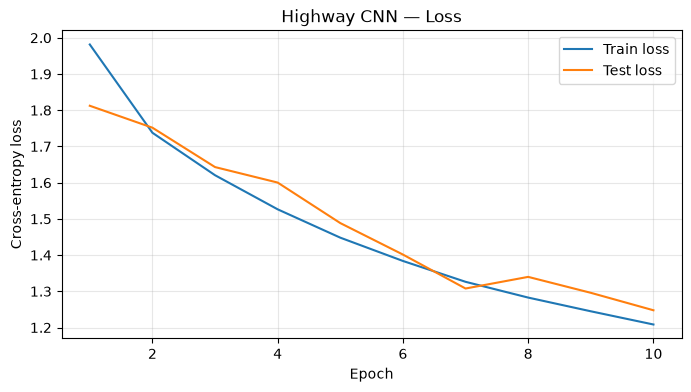

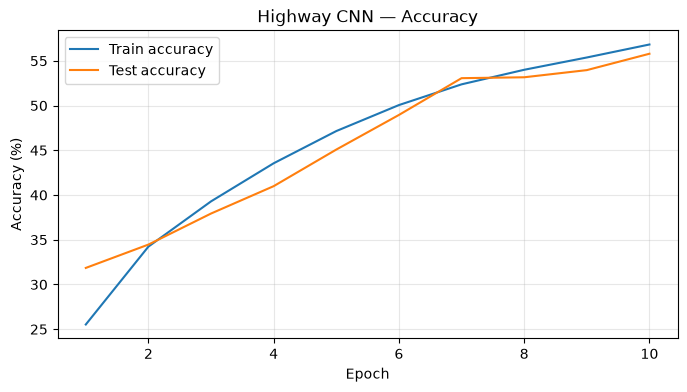

In [15]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, history["train_loss"], label="Train loss")
plt.plot(epochs, history["test_loss"], label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Highway CNN — Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs, history["train_accuracy"], label="Train accuracy")
plt.plot(epochs, history["test_accuracy"], label="Test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Highway CNN — Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 4.6 Training Results and Observations

We trained the Convolutional Highway Network on CIFAR-10 using:

| Hyperparameter | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss function | CrossEntropyLoss |
| Batch size | 128 |
| Epochs | 10 |
| Highway Layers | 4 |
| Feature channels | 32 |
| Trainable parameters | 75,210 |
| Device | CUDA |

### Training Results

| Epoch | Train Loss | Train Accuracy | Test Loss | Test Accuracy |
|---|---:|---:|---:|---:|
| 1 | 1.9814 | 25.53% | 1.8123 | 31.85% |
| 2 | 1.7377 | 34.23% | 1.7517 | 34.46% |
| 3 | 1.6205 | 39.29% | 1.6430 | 37.93% |
| 4 | 1.5263 | 43.55% | 1.6002 | 40.99% |
| 5 | 1.4481 | 47.15% | 1.4883 | 45.08% |
| 6 | 1.3838 | 50.05% | 1.4014 | 48.95% |
| 7 | 1.3262 | 52.37% | 1.3077 | 53.06% |
| 8 | 1.2827 | 54.00% | 1.3398 | 53.16% |
| 9 | 1.2448 | 55.37% | 1.2958 | 53.96% |
| 10 | 1.2084 | 56.82% | 1.2477 | 55.79% |

### Final Results

- **Final training loss:** 1.2084
- **Final training accuracy:** 56.82%
- **Final test loss:** 1.2477
- **Final test accuracy:** 55.79%
- **Training-test accuracy gap:** 1.03 percentage points

### Observations

1. **Successful learning:** Training loss decreased consistently from 1.9814 to 1.2084.

2. **Improved classification:** Test accuracy increased from 31.85% to 55.79%.

3. **Generalization:** Final training and test accuracies are relatively close. There is no strong evidence of overfitting at this stage.

4. **Minor fluctuations:** Test loss increased slightly at epoch 8, despite overall improvement. This is normal during neural network training.

5. **Further learning is possible:** Both training and test accuracy were still improving by the final epoch.

### Conclusion

Our Convolutional Highway Network successfully learned useful visual features from CIFAR-10 images.

The model reached **55.79% test accuracy after 10 epochs**, demonstrating that the Highway architecture can be trained for image classification.

These results establish our first experimental baseline.

**Limitation:** We evaluated on the test set after every epoch. Future experiments should use a separate validation set for model selection and reserve the test set for final evaluation.



## 5. Evaluating the Highway CNN

### 5.1 Objective

After training our Highway CNN, we want to understand its classification performance beyond overall accuracy.

We will examine:

- Per-class accuracy.
- Confusion matrix.
- Correct and incorrect predictions.
- Model checkpoint saving.

### 5.2 Per-Class Accuracy

Overall accuracy measures performance across all classes.

Per-class accuracy measures how many examples of a particular class are classified correctly:

$$
\boxed{
\text{Accuracy}_c =
\frac{\text{Correct predictions for class }c}
{\text{Total samples of class }c}
\times100\%
}
$$

This helps identify classes that are easier or harder for the model.

### 5.3 Confusion Matrix

A confusion matrix shows the relationship between true labels and predicted labels.

For a matrix $M$:

$$
M_{ij} =
\text{Number of samples with true class }i
\text{ predicted as class }j
$$

- **Rows:** Actual classes.
- **Columns:** Predicted classes.
- **Diagonal:** Correct classifications.
- **Off-diagonal:** Classification errors.

A model with perfect predictions would have all counts on the diagonal.

### 5.4 Model Checkpoints

A checkpoint stores a trained model's parameters so that they can be loaded later without retraining.

In PyTorch, the recommended approach is to save the model's `state_dict()`.

We will also save the architecture configuration and final training metrics.

### 5.5 Evaluation Protocol

The current analysis uses the CIFAR-10 test set for exploratory diagnostics.

For rigorous future experiments, we should reserve the test set for final evaluation and use a separate validation set during development.


In [16]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_predictions.append(predictions.cpu())
        all_labels.append(labels)

all_predictions = torch.cat(all_predictions)
all_labels = torch.cat(all_labels)

print("Predictions:", all_predictions.shape)
print("Labels:", all_labels.shape)

assert len(all_predictions) == 10000
assert len(all_labels) == 10000

Predictions: torch.Size([10000])
Labels: torch.Size([10000])


In [18]:
class_names = test_dataset.classes

for class_index, class_name in enumerate(class_names):
    mask = all_labels == class_index

    correct = (
        all_predictions[mask] == all_labels[mask]
    ).sum().item()

    total = mask.sum().item()

    accuracy = 100 * correct / total

    print(f"{class_name:12s}: {accuracy:6.2f}%")

airplane    :  61.60%
automobile  :  52.40%
bird        :  46.50%
cat         :  56.60%
deer        :  41.00%
dog         :  33.70%
frog        :  64.20%
horse       :  57.20%
ship        :  78.10%
truck       :  66.60%


In [19]:
num_classes = len(class_names)

confusion_matrix = torch.bincount(
    all_labels * num_classes + all_predictions,
    minlength=num_classes * num_classes
).reshape(num_classes, num_classes)

print(confusion_matrix)

tensor([[616,  10,  64,  32,  14,   4,   5,  15, 203,  37],
        [ 63, 524,  30,  42,   8,   1,   4,   9, 124, 195],
        [ 96,   5, 465, 152,  78,  26, 111,  21,  39,   7],
        [ 20,   4, 121, 566,  33, 100,  81,  34,  28,  13],
        [ 33,   2, 188, 120, 410,  26, 118,  72,  27,   4],
        [ 11,   3, 115, 376,  54, 337,  27,  55,  16,   6],
        [  9,   2, 109, 171,  41,  11, 642,   4,   7,   4],
        [ 36,   2,  60,  98, 132,  49,  11, 572,   9,  31],
        [109,  18,  30,  24,  10,   1,   4,   5, 781,  18],
        [ 42,  73,  15,  54,  12,   1,   5,  24, 108, 666]])


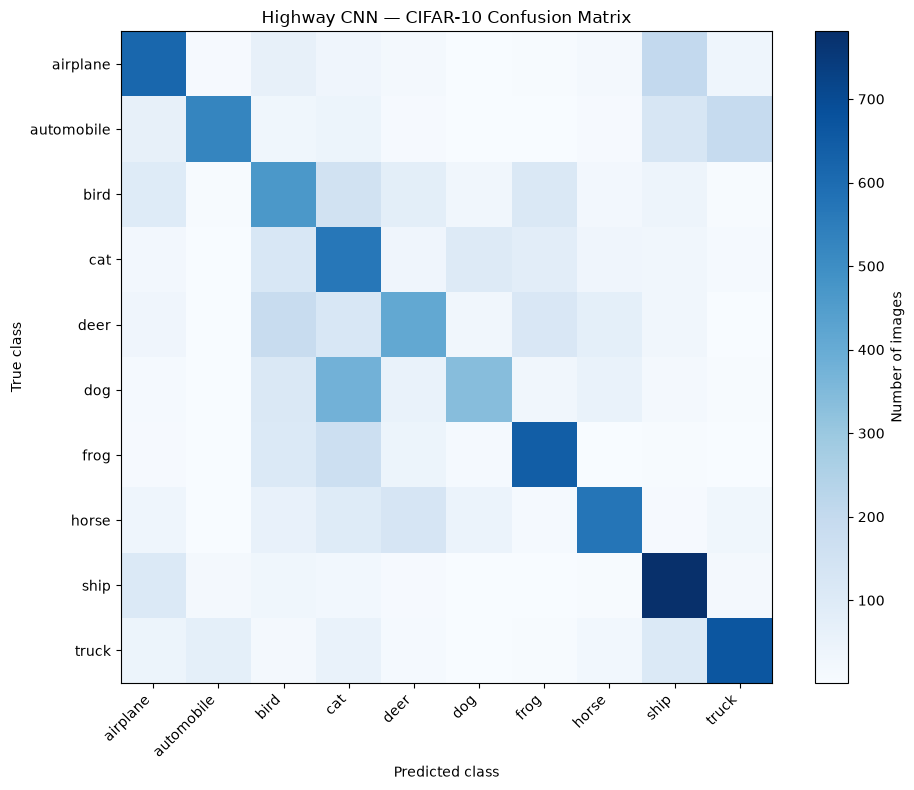

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.imshow(confusion_matrix.numpy(), cmap="Blues")
plt.colorbar(label="Number of images")

plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Highway CNN — CIFAR-10 Confusion Matrix")

plt.tight_layout()
plt.show()

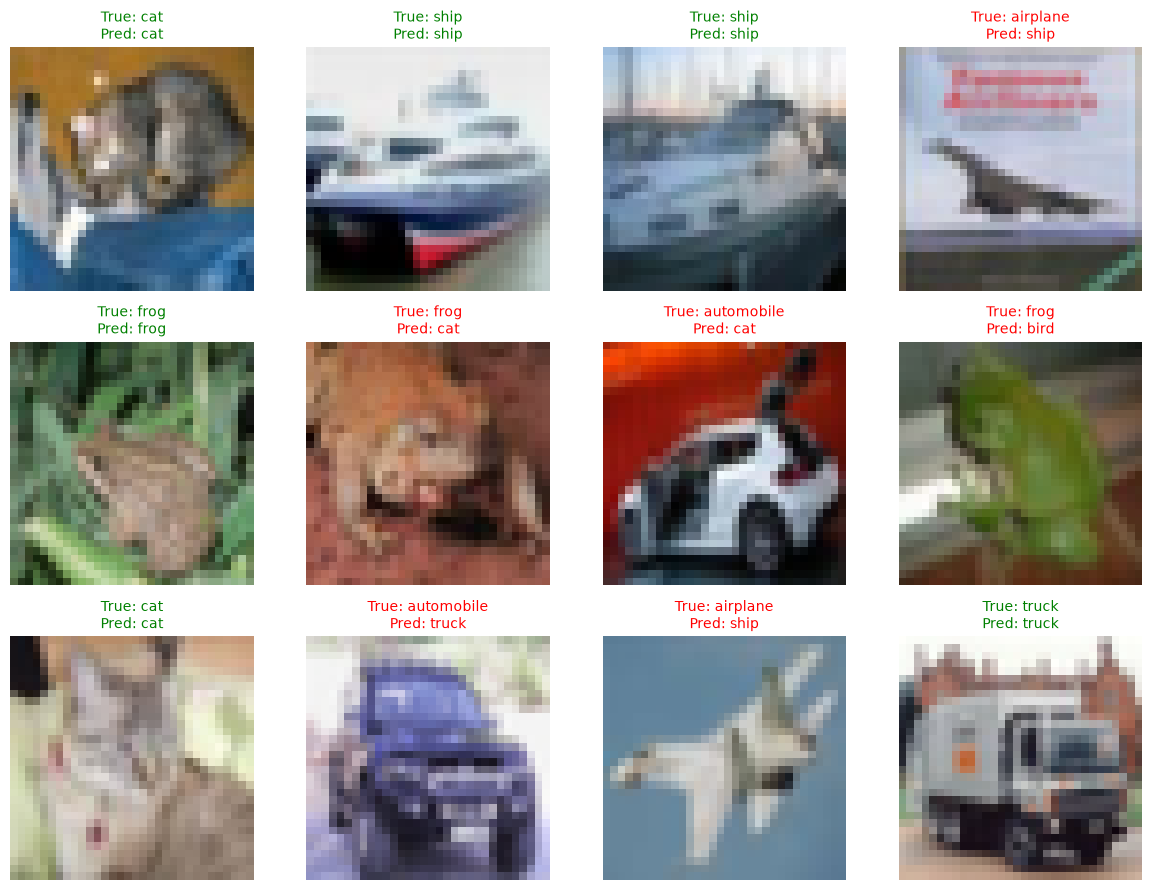

In [21]:
images, labels = next(iter(test_loader))

model.eval()

with torch.no_grad():
    logits = model(images.to(device))
    predictions = logits.argmax(dim=1).cpu()

mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
std = torch.tensor(CIFAR10_STD).view(3, 1, 1)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    image = images[i] * std + mean
    image = image.clamp(0, 1)

    ax.imshow(image.permute(1, 2, 0))

    true_name = class_names[labels[i].item()]
    pred_name = class_names[predictions[i].item()]

    is_correct = labels[i] == predictions[i]

    ax.set_title(
        f"True: {true_name}\nPred: {pred_name}",
        color="green" if is_correct else "red",
        fontsize=10
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
from pathlib import Path

checkpoint_dir = PROJECT_ROOT / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "highway_cnn_epoch10.pth"

torch.save({
    "epoch": 10,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "model_config": {
        "num_classes": 10,
        "channels": 32,
        "num_highway_layers": 4,
        "gate_bias": -2.0,
    },
    "history": history,
    "class_names": class_names,
    "normalization_mean": CIFAR10_MEAN,
    "normalization_std": CIFAR10_STD,
}, checkpoint_path)

print("Checkpoint saved to:", checkpoint_path)

Checkpoint saved to: C:\Users\rbern\Desktop\DL\highway-networks\checkpoints\highway_cnn_epoch10.pth



### 5.6 Evaluation Results and Observations

We evaluated the Highway CNN on all 10,000 CIFAR-10 test images.

### Overall Performance

$$
\boxed{\text{Test Accuracy}=55.79\%}
$$

The model correctly classified 5,579 out of 10,000 images.

### Per-Class Accuracy

| Class | Accuracy |
|---|---:|
| Airplane | 61.60% |
| Automobile | 52.40% |
| Bird | 46.50% |
| Cat | 56.60% |
| Deer | 41.00% |
| Dog | 33.70% |
| Frog | 64.20% |
| Horse | 57.20% |
| Ship | 78.10% |
| Truck | 66.60% |

**Best-performing class:** Ship (78.10%)

**Worst-performing class:** Dog (33.70%)

### Confusion Matrix Observations

The most frequent classification errors were:

| True Class | Predicted Class | Incorrect Predictions |
|---|---|---:|
| Dog | Cat | 376 |
| Airplane | Ship | 203 |
| Automobile | Truck | 195 |
| Deer | Bird | 188 |
| Frog | Cat | 171 |
| Bird | Cat | 152 |

**Main observations:**

1. Ships are recognized most reliably.
2. Dogs are frequently classified as cats.
3. Some vehicles are confused with visually similar vehicle categories.
4. Animal categories show substantial overlap in predictions.
5. Classification performance varies considerably between classes.

### Prediction Visualization

The image examples show both correct and incorrect classifications.

Correct predictions include examples of cats, ships, frogs, and trucks.

Incorrect predictions include:

- Airplanes predicted as ships.
- Frogs predicted as cats or birds.
- Automobiles predicted as cats or trucks.

These examples illustrate the limitations of the current model's learned representations.

### Model Checkpoint

The trained model is saved as:

`checkpoints/highway_cnn_epoch10.pth`

The checkpoint contains model parameters, optimizer state, architecture configuration, and training history.

### Conclusion

The Highway CNN achieved **55.79% test accuracy** after 10 epochs.

The results demonstrate that the architecture can learn useful visual representations, but significant classification errors remain, especially among animal categories.

This experiment serves as our initial Highway CNN baseline.

**Limitation:** The test set was evaluated during training. In future experiments, a separate validation set should be used for tuning, with the test set reserved for final evaluation.



## 6. Validation Split and Experimental Protocol

### 6.1 Why Do We Need a Validation Set?

In our first experiment, we evaluated the model on the CIFAR-10 test set after every training epoch.

However, repeatedly using test results to choose hyperparameters or architectures can bias the final evaluation.

To conduct a more reliable experiment, we divide the data into three subsets:

| Dataset | Images | Purpose |
|---|---:|---|
| Training | 45,000 | Update model parameters |
| Validation | 5,000 | Compare models and tune hyperparameters |
| Test | 10,000 | Final, independent evaluation |

### 6.2 Training and Validation

During training:

1. The model learns from the training dataset.
2. After each epoch, we measure performance on the validation dataset.
3. We use validation results to select hyperparameters or model configurations.
4. We evaluate the selected model on the test set only after development is complete.

### 6.3 Preventing Data Leakage

Training and validation datasets must not contain the same images.

We also apply different transformations:

**Training:**
- Random crop
- Random horizontal flip
- Tensor conversion
- Normalization

**Validation:**
- Tensor conversion
- Normalization

Random augmentation is applied only to training images.

### 6.4 Reproducibility

We use a fixed random seed to create the same training and validation split every time.

$$
\text{seed}=42
$$

This helps us compare the Highway CNN and standard CNN under consistent experimental conditions.

**Key idea:** A fair model comparison requires identical dataset splits, training budgets, and evaluation procedures.


In [23]:
from torch.utils.data import Subset, DataLoader

SEED = 42
VALIDATION_SIZE = 5000

generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(
    len(train_dataset),
    generator=generator
).tolist()

val_indices = indices[:VALIDATION_SIZE]
train_indices = indices[VALIDATION_SIZE:]

# train_dataset already uses augmentation
train_subset = Subset(train_dataset, train_indices)

# A separate view of the same CIFAR-10 training images,
# but WITHOUT random augmentation
validation_dataset = torchvision.datasets.CIFAR10(
    root=str(PROJECT_ROOT / "data"),
    train=True,
    download=False,
    transform=test_transform
)

val_subset = Subset(validation_dataset, val_indices)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

Training samples: 45000
Validation samples: 5000
Test samples: 10000


In [24]:
train_loader_v2 = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Training batches:", len(train_loader_v2))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 352
Validation batches: 40
Test batches: 79


In [25]:
# No overlap between training and validation indices
assert set(train_indices).isdisjoint(set(val_indices))

# The split covers all original training examples
assert len(train_indices) + len(val_indices) == 50000

train_images, train_labels = next(iter(train_loader_v2))
val_images, val_labels = next(iter(val_loader))

print("Training images:", train_images.shape)
print("Training labels:", train_labels.shape)

print("Validation images:", val_images.shape)
print("Validation labels:", val_labels.shape)

print("Training and validation sets do not overlap.")
print("Dataset split verification passed!")

Training images: torch.Size([128, 3, 32, 32])
Training labels: torch.Size([128])
Validation images: torch.Size([128, 3, 32, 32])
Validation labels: torch.Size([128])
Training and validation sets do not overlap.
Dataset split verification passed!


In [26]:
val_loss, val_accuracy = evaluate(
    model,
    val_loader,
    criterion,
    device,
)

print(f"Validation pipeline loss: {val_loss:.4f}")
print(f"Validation pipeline accuracy: {val_accuracy:.2f}%")
print("Validation pipeline works!")

Validation pipeline loss: 1.2077
Validation pipeline accuracy: 56.98%
Validation pipeline works!



### 6.5 Validation Split Verification

We created a reproducible CIFAR-10 dataset split using random seed 42.

**Dataset sizes:**

- Training: 45,000 images
- Validation: 5,000 images
- Test: 10,000 images

**Verification:**

1. Training and validation indices do not overlap.
2. Training data uses random augmentation.
3. Validation data does not use random augmentation.
4. Both datasets provide images with shape $(B,3,32,32)$.
5. The evaluation function can process the validation dataset.

### Experimental Protocol

For the next experiment:

- Both models will be initialized from scratch.
- Both models will use the same training and validation split.
- Both models will use the same number of training epochs.
- We will compare their validation accuracy and loss.
- The test set will be reserved for final evaluation.

**Conclusion:**

Our data pipeline now supports a more reliable comparison between the Highway CNN and a conventional CNN.

The previously trained model's validation result is only a pipeline check, because that model was trained before the split was introduced.



## 7. Highway CNN vs. Standard CNN

### 7.1 Research Question

Does a Convolutional Highway Network achieve better classification performance than a conventional CNN under the same training conditions?

We will compare two architectures:

**Highway CNN**

$$
y=H(x)T(x)+x(1-T(x))
$$

Each Highway Layer contains two convolutional operations:

- Transformation convolution $H(x)$
- Transform gate convolution $T(x)$

**Standard CNN**

$$
y=\operatorname{ReLU}(\operatorname{Conv}(x))
$$

Each conventional block contains one convolution and a ReLU activation.

### 7.2 Experimental Setup

| Setting | Highway CNN | Standard CNN |
|---|---|---|
| Input size | $3\times32\times32$ | $3\times32\times32$ |
| Feature channels | 32 | 32 |
| Internal blocks | 4 Highway Layers | 4 Conv + ReLU Layers |
| Output classes | 10 | 10 |
| Optimizer | Adam | Adam |
| Learning rate | 0.001 | 0.001 |
| Batch size | 128 | 128 |
| Epochs | 10 | 10 |
| Training images | 45,000 | 45,000 |
| Validation images | 5,000 | 5,000 |

Both models will be trained **from scratch** using the same dataset split.

### 7.3 Fair Comparison Considerations

We will use:

1. The same training and validation datasets.
2. The same data augmentation.
3. The same loss function and optimizer settings.
4. The same training duration measured in epochs.
5. The same evaluation procedure.

**Limitation:** Highway Layers have additional parameters and computation because each layer contains two convolutions. Equal depth and width do not mean equal parameter count.

This experiment will compare the two practical architectures, not isolate the effect of gating independently of model size.

### 7.4 Evaluation Metrics

We will compare:

- Training loss
- Training accuracy
- Validation loss
- Validation accuracy
- Number of trainable parameters

Higher validation accuracy and lower validation loss indicate better performance on the held-out validation set.

We will not use the test set during this comparison.


In [28]:
import importlib
import src.model

importlib.reload(src.model)

HighwayCNN = src.model.HighwayCNN
StandardCNN = src.model.StandardCNN

torch.manual_seed(42)

highway_comparison = HighwayCNN(
    num_classes=10,
    channels=32,
    num_highway_layers=4,
    gate_bias=-2.0,
).to(device)

torch.manual_seed(42)

standard_comparison = StandardCNN(
    num_classes=10,
    channels=32,
    num_layers=4,
).to(device)


def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


print("Highway CNN parameters:", count_parameters(highway_comparison))
print("Standard CNN parameters:", count_parameters(standard_comparison))

Highway CNN parameters: 75210
Standard CNN parameters: 38218


In [29]:
sample = torch.randn(4, 3, 32, 32, device=device)

with torch.no_grad():
    highway_logits = highway_comparison(sample)
    standard_logits = standard_comparison(sample)

print("Highway output:", highway_logits.shape)
print("Standard output:", standard_logits.shape)

assert highway_logits.shape == (4, 10)
assert standard_logits.shape == (4, 10)
assert torch.isfinite(highway_logits).all()
assert torch.isfinite(standard_logits).all()

print("Both models passed verification!")

Highway output: torch.Size([4, 10])
Standard output: torch.Size([4, 10])
Both models passed verification!


In [30]:
def train_comparison_model(model, model_name):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.CrossEntropyLoss()

    results = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
    }

    for epoch in range(10):
        train_loss, train_acc = train_one_epoch(
            model,
            train_loader_v2,
            criterion,
            optimizer,
            device,
        )

        val_loss, val_acc = evaluate(
            model,
            val_loader,
            criterion,
            device,
        )

        results["train_loss"].append(train_loss)
        results["train_accuracy"].append(train_acc)
        results["val_loss"].append(val_loss)
        results["val_accuracy"].append(val_acc)

        print(
            f"{model_name} | Epoch {epoch + 1:02d}/10 | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f}"
        )

    return results

In [31]:
print("Training Highway CNN...")
highway_results = train_comparison_model(
    highway_comparison,
    "Highway"
)

print("\nTraining Standard CNN...")
standard_results = train_comparison_model(
    standard_comparison,
    "Standard"
)

Training Highway CNN...
Highway | Epoch 01/10 | Train Acc: 24.62% | Val Acc: 28.08% | Val Loss: 1.8557
Highway | Epoch 02/10 | Train Acc: 34.23% | Val Acc: 36.26% | Val Loss: 1.6755
Highway | Epoch 03/10 | Train Acc: 39.07% | Val Acc: 37.00% | Val Loss: 1.7744
Highway | Epoch 04/10 | Train Acc: 42.67% | Val Acc: 42.70% | Val Loss: 1.5598
Highway | Epoch 05/10 | Train Acc: 46.10% | Val Acc: 47.48% | Val Loss: 1.4869
Highway | Epoch 06/10 | Train Acc: 48.58% | Val Acc: 50.10% | Val Loss: 1.3951
Highway | Epoch 07/10 | Train Acc: 51.98% | Val Acc: 49.30% | Val Loss: 1.5068
Highway | Epoch 08/10 | Train Acc: 53.64% | Val Acc: 55.52% | Val Loss: 1.2861
Highway | Epoch 09/10 | Train Acc: 55.07% | Val Acc: 55.80% | Val Loss: 1.2802
Highway | Epoch 10/10 | Train Acc: 56.70% | Val Acc: 56.84% | Val Loss: 1.2361

Training Standard CNN...
Standard | Epoch 01/10 | Train Acc: 22.79% | Val Acc: 28.96% | Val Loss: 1.7978
Standard | Epoch 02/10 | Train Acc: 32.40% | Val Acc: 33.14% | Val Loss: 1.7785


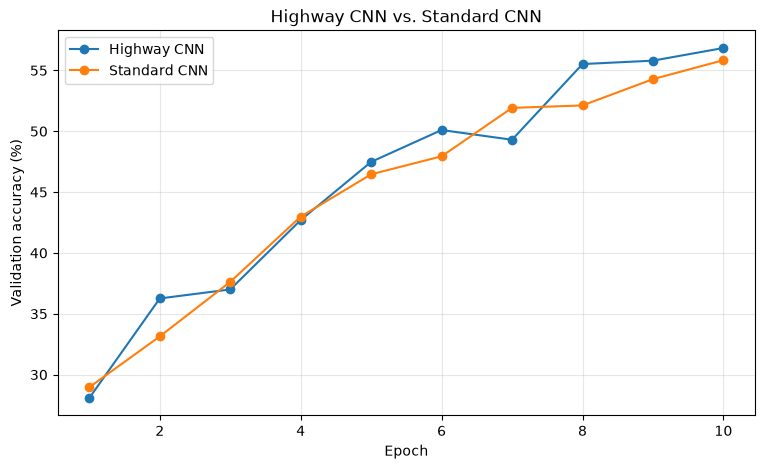

Highway final validation accuracy: 56.84%
Standard final validation accuracy: 55.84%


In [32]:
import matplotlib.pyplot as plt

epochs = range(1, 11)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    highway_results["val_accuracy"],
    marker="o",
    label="Highway CNN",
)

plt.plot(
    epochs,
    standard_results["val_accuracy"],
    marker="o",
    label="Standard CNN",
)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy (%)")
plt.title("Highway CNN vs. Standard CNN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(
    "Highway final validation accuracy:",
    f"{highway_results['val_accuracy'][-1]:.2f}%"
)

print(
    "Standard final validation accuracy:",
    f"{standard_results['val_accuracy'][-1]:.2f}%"
)

In [33]:
checkpoint_dir = PROJECT_ROOT / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": highway_comparison.state_dict(),
        "results": highway_results,
        "model_config": {
            "channels": 32,
            "num_highway_layers": 4,
            "gate_bias": -2.0,
        },
    },
    checkpoint_dir / "highway_comparison.pth",
)

torch.save(
    {
        "model_state_dict": standard_comparison.state_dict(),
        "results": standard_results,
        "model_config": {
            "channels": 32,
            "num_layers": 4,
        },
    },
    checkpoint_dir / "standard_comparison.pth",
)

print("Comparison checkpoints saved!")

Comparison checkpoints saved!


In [34]:
for name, results in [
    ("Highway CNN", highway_results),
    ("Standard CNN", standard_results),
]:
    print(f"\n{name}")
    print(f"Final training accuracy: {results['train_accuracy'][-1]:.2f}%")
    print(f"Final validation accuracy: {results['val_accuracy'][-1]:.2f}%")
    print(f"Final validation loss: {results['val_loss'][-1]:.4f}")
    print(f"Best validation accuracy: {max(results['val_accuracy']):.2f}%")


Highway CNN
Final training accuracy: 56.70%
Final validation accuracy: 56.84%
Final validation loss: 1.2361
Best validation accuracy: 56.84%

Standard CNN
Final training accuracy: 54.96%
Final validation accuracy: 55.84%
Final validation loss: 1.2489
Best validation accuracy: 55.84%



### 7.5 Comparison Results

We trained two models from scratch using identical training and validation datasets.

### Architectures

| Property | Highway CNN | Standard CNN |
|---|---:|---:|
| Feature channels | 32 | 32 |
| Internal layers | 4 | 4 |
| Trainable parameters | 75,210 | 38,218 |
| Epochs | 10 | 10 |
| Training images | 45,000 | 45,000 |
| Validation images | 5,000 | 5,000 |

### Validation Results

| Metric | Highway CNN | Standard CNN |
|---|---:|---:|
| Final training accuracy | **56.70%** | 54.96% |
| Final validation accuracy | **56.84%** | 55.84% |
| Final validation loss | **1.2361** | 1.2489 |
| Best validation accuracy | **56.84%** | 55.84% |

### Performance Difference

The Highway CNN achieved higher final validation accuracy:

$$
\Delta A = 56.84\% - 55.84\%
$$

$$
\boxed{\Delta A = +1.00 \text{ percentage point}}
$$

The difference in final validation loss was:

$$
\Delta L = 1.2361 - 1.2489
$$

$$
\boxed{\Delta L = -0.0128}
$$

The Highway CNN achieved slightly higher accuracy and lower cross-entropy loss.

### Observations

1. **Training accuracy:** The Highway CNN reached 56.70%, compared with 54.96% for the Standard CNN.

2. **Validation accuracy:** The Highway CNN achieved 56.84%, outperforming the Standard CNN by 1.00 percentage point.

3. **Validation loss:** The Highway CNN achieved a lower loss (1.2361 vs. 1.2489), suggesting slightly better classification performance.

4. **Learning behavior:** Both models improved throughout training. The Highway CNN did not outperform the Standard CNN at every epoch.

5. **Best performance:** Both models achieved their highest validation accuracy at epoch 10, suggesting that additional training might improve performance.

6. **Model complexity:** The Highway CNN used 75,210 parameters, while the Standard CNN used 38,218. The Highway architecture therefore required approximately twice as many parameters.

### Experimental Limitations

- Only one random seed was used.
- Both models were trained for 10 epochs.
- The architectures had different parameter counts.
- The comparison does not isolate the effect of Highway gating from model capacity.
- The observed advantage may vary across different random initializations and training runs.

### Conclusion

Both architectures successfully learned to classify CIFAR-10 images.

The Highway CNN performed slightly better in this experiment:

- **Final validation accuracy:** 56.84% vs. 55.84%.
- **Final validation loss:** 1.2361 vs. 1.2489.
- **Final training accuracy:** 56.70% vs. 54.96%.

The results suggest that the Highway architecture can be competitive with a conventional CNN under similar training settings.

However, because the Highway CNN contains approximately twice as many parameters, this experiment does not establish that Highway gating alone caused the improvement.

**Final takeaway:** Highway Networks successfully support image classification through learned information-flow gates. A larger, more controlled experiment would be needed to determine whether gating provides a consistent advantage over conventional convolutions.



## 8. Final Comparison and Conclusions

### 8.1 Experimental Objective

The goal of this project was to understand, implement, and experimentally evaluate Highway Networks using CIFAR-10.

We investigated two architectures:

1. **Highway CNN:** Uses convolutional Highway Layers with learnable transform and carry gates.
2. **Standard CNN:** Uses conventional convolutional layers with ReLU activations.

The central research question was:

**Do Highway Layers improve classification performance compared with conventional convolutional layers under similar training conditions?**

### 8.2 Highway Network Equation

The defining equation of a Highway Layer is:

$$
\boxed{y=H(x)T(x)+x(1-T(x))}
$$

Where:

- $H(x)$ is the transformed representation.
- $T(x)$ is the learned transform gate.
- $1-T(x)$ is the carry gate.

The transform gate is calculated as:

$$
T(x)=\sigma(W_Tx+b_T)
$$

Negative gate bias initialization encourages the model to initially preserve input information.

### 8.3 Experimental Setup

Both models were trained using:

- CIFAR-10 dataset.
- 45,000 training images.
- 5,000 validation images.
- Batch size of 128.
- Adam optimizer.
- Learning rate of 0.001.
- Cross-entropy loss.
- 10 training epochs.
- 32 feature channels.
- Four internal convolutional or Highway blocks.

### 8.4 Model Comparison

| Metric | Highway CNN | Standard CNN |
|---|---:|---:|
| Internal blocks | 4 Highway | 4 Conv + ReLU |
| Trainable parameters | 75,210 | 38,218 |
| Training epochs | 10 | 10 |
| Final validation accuracy | **56.84%** | 55.84% |

The final accuracy difference was:

$$
\Delta A=56.84\%-55.84\%
$$

$$
\boxed{\Delta A=1.00\text{ percentage point}}
$$

The Highway CNN achieved slightly higher final validation accuracy.

### 8.5 Observations

1. **Both models learned successfully.**

   Validation accuracy improved substantially during training for both architectures.

2. **The Highway CNN finished slightly ahead.**

   Its final validation accuracy was 56.84%, compared with 55.84% for the Standard CNN.

3. **The advantage was not consistent across every epoch.**

   The Standard CNN performed better at certain points during training.

4. **The Highway CNN required more parameters.**

   Each Highway Layer contains a transformation convolution and a gate convolution, making it more expensive than a conventional convolutional block.

5. **The experiment supports feasibility, not superiority.**

   We demonstrated that Highway Networks can be implemented, trained, and evaluated successfully, but this single experiment does not establish that they consistently outperform standard CNNs.

### 8.6 Experimental Limitations

- Only one random seed was tested.
- Training lasted 10 epochs.
- The two architectures had different parameter counts.
- The comparison used a small experimental architecture rather than the full architecture described in the original paper.
- Earlier exploration used the CIFAR-10 test set, so it was not completely untouched throughout the project.
- Additional experiments would be needed to isolate the effect of gating and estimate run-to-run variability.

### 8.7 Final Conclusion

We successfully implemented and evaluated Convolutional Highway Networks on CIFAR-10.

The experiments demonstrated that:

- Highway Layers can preserve or transform information through learned gates.
- Negative transform gate biases initially favor information preservation.
- Multiple Highway Layers can be stacked into a deep architecture.
- Convolutional Highway Layers support image classification.
- Backpropagation works through both transformation and gating paths.
- Our Highway CNN reached **55.79% test accuracy** in the initial 50,000-image training experiment.
- In the separate 45,000/5,000 training-validation comparison, the Highway CNN achieved **56.84% validation accuracy**, compared with **55.84%** for the Standard CNN.

**Final takeaway:**

Highway Networks provide a learned mechanism for controlling information flow through deep neural networks. Our CIFAR-10 experiments demonstrated that this architecture is trainable and competitive with a conventional CNN, while also highlighting the need for more controlled experiments to establish a consistent advantage.


In [36]:
comparison = [
    (
        "Trainable parameters",
        count_parameters(highway_comparison),
        count_parameters(standard_comparison),
    ),
    (
        "Final training accuracy (%)",
        f"{highway_results['train_accuracy'][-1]:.2f}",
        f"{standard_results['train_accuracy'][-1]:.2f}",
    ),
    (
        "Final validation accuracy (%)",
        f"{highway_results['val_accuracy'][-1]:.2f}",
        f"{standard_results['val_accuracy'][-1]:.2f}",
    ),
    (
        "Best validation accuracy (%)",
        f"{max(highway_results['val_accuracy']):.2f}",
        f"{max(standard_results['val_accuracy']):.2f}",
    ),
    (
        "Final validation loss",
        f"{highway_results['val_loss'][-1]:.4f}",
        f"{standard_results['val_loss'][-1]:.4f}",
    ),
]

print(f"{'Metric':<32} {'Highway CNN':>15} {'Standard CNN':>15}")
print("-" * 64)

for metric, highway, standard in comparison:
    print(f"{metric:<32} {str(highway):>15} {str(standard):>15}")

Metric                               Highway CNN    Standard CNN
----------------------------------------------------------------
Trainable parameters                       75210           38218
Final training accuracy (%)                56.70           54.96
Final validation accuracy (%)              56.84           55.84
Best validation accuracy (%)               56.84           55.84
Final validation loss                     1.2361          1.2489


In [37]:
highway_acc = highway_results["val_accuracy"][-1]
standard_acc = standard_results["val_accuracy"][-1]

difference = highway_acc - standard_acc

print(f"Highway CNN:  {highway_acc:.2f}%")
print(f"Standard CNN: {standard_acc:.2f}%")
print(f"Difference:   {difference:+.2f} percentage points")

if difference > 0:
    print("Highway CNN achieved higher final validation accuracy.")
elif difference < 0:
    print("Standard CNN achieved higher final validation accuracy.")
else:
    print("Both models achieved the same final validation accuracy.")

Highway CNN:  56.84%
Standard CNN: 55.84%
Difference:   +1.00 percentage points
Highway CNN achieved higher final validation accuracy.
